
# 1. Heatmap: evolució de les anomalies de temperatura global

## Objectiu

Representar les anomalies mensuals de temperatura global mitjançant un mapa de calor (*heatmap*), utilizant els anys en l'eix vertical, els mesos en l'eix horitzontal i el color per codificar la magnitud de la anomalia tèrmica.

Aquesta visualització permet identificar patrons temporals, diferències estacionals i l'evolució de les anomaless positives i negatives al llarg del periode estudiat.


In [5]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ruta del fitxer CSV
BASE_DIR = Path.cwd().resolve()

CSV_PATH = (
    BASE_DIR.parent
    / "dades heatmap"
    / "global-temperature-anomalies-by-month.csv"
)

# Carregar les dades
df = pd.read_csv(CSV_PATH)

# Comprovar el contingut
display(df.head())

print("Dimensions del conjunt de dades:", df.shape)
print("\nTipus de dades:")
print(df.dtypes)

print("\nValors absents:")
print(df.isna().sum())


,Entity,Year,Temperature anomaly
0,April,1940,-0.604778
1,April,1941,-0.806757
2,April,1942,-0.803393
3,April,1943,-0.772172
4,April,1944,-0.630437


Dimensions del conjunt de dades: (1041, 3)

Tipus de dades:
Entity                     str
Year                     int64
Temperature anomaly    float64
dtype: object

Valors absents:
Entity                 0
Year                   0
Temperature anomaly    0
dtype: int64


In [6]:

# Ordenar els mesos cronològicament
mesos = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Crear una matriu amb els anys a les files i els mesos a les columnes
heatmap_data = (
    df.pivot(
        index="Year",
        columns="Entity",
        values="Temperature anomaly"
    )
    .reindex(columns=mesos)
    .sort_index()
)

display(heatmap_data.head())

print("Dimensions de la matriu:", heatmap_data.shape)


Entity,January,February,March,April,May,June,July,August,September,October,November,December
Year,,,,,,,,,,,,
1940,-0.945041,-0.857368,-0.885080,-0.604778,-0.516183,-0.668176,-0.450294,-0.499124,-0.634774,-0.813478,-0.759418,-0.599910
1941,-0.680809,-0.543087,-0.713651,-0.806757,-0.607295,-0.492791,-0.543528,-0.474840,-0.854121,-0.508422,-0.784723,-0.691267
1942,-0.561256,-0.796718,-0.708552,-0.803393,-0.608633,-0.679663,-0.725219,-0.748476,-0.741255,-0.721736,-0.874621,-0.819641
1943,-0.817303,-0.684020,-0.885442,-0.772172,-0.629622,-0.762594,-0.742569,-0.776564,-0.709731,-0.649956,-0.676369,-0.610204
1944,-0.389549,-0.499270,-0.458527,-0.630437,-0.598088,-0.516790,-0.532729,-0.468554,-0.412411,-0.459703,-0.692009,-0.761890


Dimensions de la matriu: (87, 12)


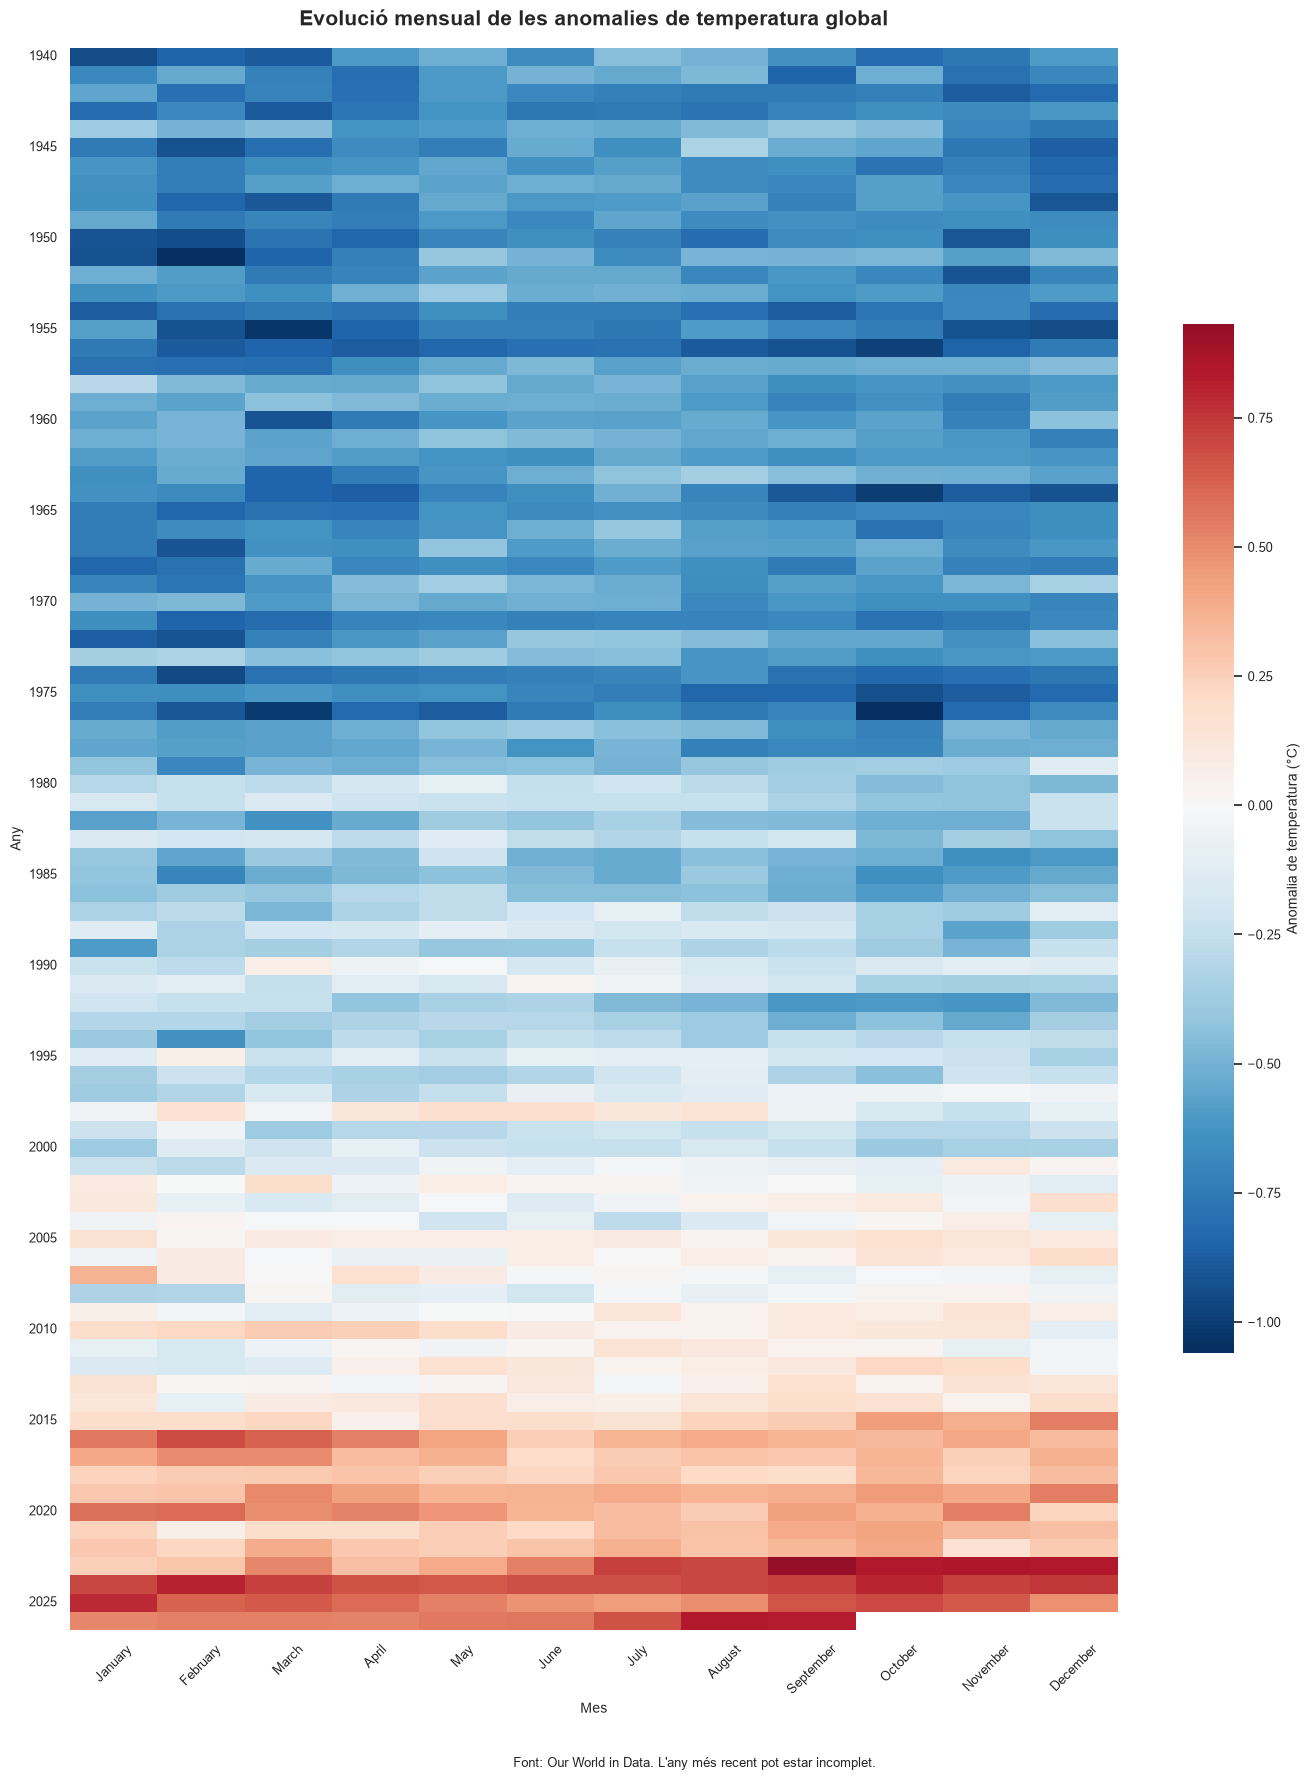

In [7]:

sns.set_theme(style="white", font_scale=0.85)

fig, ax = plt.subplots(figsize=(14, 18))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    linewidths=0,
    cbar_kws={
        "label": "Anomalia de temperatura (°C)",
        "shrink": 0.65
    },
    ax=ax
)

ax.set_title(
    "Evolució mensual de les anomalies de temperatura global",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Mes")
ax.set_ylabel("Any")

# Mostrar una etiqueta cada cinc anys
marques_anys = list(range(0, len(heatmap_data), 5))

ax.set_yticks([i + 0.5 for i in marques_anys])
ax.set_yticklabels(
    heatmap_data.index[marques_anys],
    rotation=0
)

ax.tick_params(axis="x", rotation=45)

fig.text(
    0.5,
    0.015,
    "Font: Our World in Data. L'any més recent pot estar incomplet.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.show()


In [8]:

# Crear la carpeta de sortida si no existeix
OUTPUT_DIR = BASE_DIR / "grafics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Desar el mapa de calor
output_path = OUTPUT_DIR / "heatmap_temperatura.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

print(f"Mapa de calor desat a: {output_path}")


Mapa de calor desat a: D:\ESTUDIS\Master data science - UOC\1r_Semestre\Visualització de Dades\PAC2\entregable\grafics\heatmap_temperatura.png



## Interpretació dels resultats

El mapa de calor mostra una evolució temporal de les anomalies de temperatura global. En les primeres dècades representades predominen els valors negatius, mentre que en els anys més recents s'observa un predomini de valors positius i de més magnitud.

La representació permet identificar aquest canvi de patró d'una manera visual i comparar-ne la distribució mensual. Les cel·les sense color corresponen a períodes sense dades disponibles.

L'objectiu comunicatiu és facilitar la identificació de patrons temporals i mostrar com han evolucionat les anomalies de temperatura global al llarg del període estudiat.
